# Практическая работа 2. Создание графа, расчёт характеристик и визуализация

**Задание:**
1. Создать граф, рассчитать характеристики.
2. Взять датасет и сделать разные визуализации графа, в том числе интерактивные
   ([vis-network](https://visjs.github.io/vis-network/examples/), [PyVis](https://pyvis.readthedocs.io/en/latest/)).

План работы:
- **Часть 1.** Строим собственный граф «вручную» (граф совместной работы небольшой команды разработки) и считаем характеристики из ноутбука *Networkx*.
- **Часть 2.** Берём реальные датасеты:
  - *Dolphins* (KONECT): 62 дельфина, 159 связей «часто наблюдались вместе»;
  - *Les Misérables* (встроен в NetworkX): 77 персонажей романа, вес ребра равен числу совместных сцен.

  Для них строим статические визуализации (разные укладки, сообщества, центральности, распределение степеней, матрица смежности) и интерактивные (PyVis и vis-network на чистом JS).

In [1]:
# !pip install networkx pyvis matplotlib pandas
import os, tarfile, urllib.request, html, json, warnings
from collections import Counter

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from networkx.algorithms import community
from IPython.display import HTML, display

plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
print("networkx", nx.__version__)

networkx 3.2.1


## Часть 1. Создаём граф и рассчитываем характеристики

Граф: команда из 10 человек. Ребро означает, что двое работали над общей задачей,
**вес** ребра равен числу совместных задач за спринт. У каждого узла есть атрибут `role`.

In [2]:
G = nx.Graph()
people = {
    "Анна": "тимлид", "Борис": "backend", "Вера": "backend", "Глеб": "frontend",
    "Дина": "frontend", "Егор": "QA", "Жанна": "аналитик", "Зоя": "дизайнер",
    "Илья": "DevOps", "Кира": "data scientist",
}
for name, role in people.items():
    G.add_node(name, role=role)

G.add_weighted_edges_from([
    ("Анна", "Борис", 5), ("Анна", "Вера", 4), ("Анна", "Глеб", 3), ("Анна", "Жанна", 6),
    ("Борис", "Вера", 7), ("Борис", "Илья", 3), ("Вера", "Илья", 2), ("Вера", "Кира", 4),
    ("Глеб", "Дина", 8), ("Глеб", "Зоя", 5), ("Дина", "Зоя", 4), ("Дина", "Егор", 3),
    ("Егор", "Борис", 2), ("Егор", "Глеб", 2), ("Жанна", "Кира", 5), ("Жанна", "Зоя", 2),
])
print("узлы:", list(G.nodes()))
print("рёбра:", list(G.edges(data="weight")))

узлы: ['Анна', 'Борис', 'Вера', 'Глеб', 'Дина', 'Егор', 'Жанна', 'Зоя', 'Илья', 'Кира']
рёбра: [('Анна', 'Борис', 5), ('Анна', 'Вера', 4), ('Анна', 'Глеб', 3), ('Анна', 'Жанна', 6), ('Борис', 'Вера', 7), ('Борис', 'Илья', 3), ('Борис', 'Егор', 2), ('Вера', 'Илья', 2), ('Вера', 'Кира', 4), ('Глеб', 'Дина', 8), ('Глеб', 'Зоя', 5), ('Глеб', 'Егор', 2), ('Дина', 'Зоя', 4), ('Дина', 'Егор', 3), ('Жанна', 'Кира', 5), ('Жанна', 'Зоя', 2)]


In [3]:
print("Соседи Анны:", list(G.neighbors("Анна")))
print("Степень Бориса:", G.degree("Борис"), "| взвешенная степень:", G.degree("Борис", weight="weight"))
print()
print("Число узлов:", G.number_of_nodes())
print("Число рёбер:", G.number_of_edges())
print("Связный:", nx.is_connected(G))
print("Радиус:", nx.radius(G))
print("Диаметр:", nx.diameter(G))
print("Центр графа:", nx.center(G), "| периферия:", nx.periphery(G))
print("Плотность: {:.3f}".format(nx.density(G)))
print("Средняя степень: {:.2f}".format(2 * G.number_of_edges() / G.number_of_nodes()))
print("Средняя длина кратчайшего пути: {:.3f}".format(nx.average_shortest_path_length(G)))
print("Ассортативность: {:.3f}".format(nx.degree_pearson_correlation_coefficient(G)))
print("Средний коэффициент кластеризации: {:.3f}".format(nx.average_clustering(G)))
print("Транзитивность: {:.3f}".format(nx.transitivity(G)))

Соседи Анны: ['Борис', 'Вера', 'Глеб', 'Жанна']
Степень Бориса: 4 | взвешенная степень: 17

Число узлов: 10
Число рёбер: 16
Связный: True
Радиус: 2
Диаметр: 4
Центр графа: ['Анна'] | периферия: ['Зоя', 'Илья']
Плотность: 0.356
Средняя степень: 3.20
Средняя длина кратчайшего пути: 1.911


Ассортативность: -0.161
Средний коэффициент кластеризации: 0.350
Транзитивность: 0.316


In [4]:
metrics = pd.DataFrame({
    "role": nx.get_node_attributes(G, "role"),
    "degree": dict(G.degree()),
    "w_degree": dict(G.degree(weight="weight")),
    "degree_c": nx.degree_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, weight="weight"),
    "pagerank": nx.pagerank(G, weight="weight"),
    "clustering": nx.clustering(G),
}).round(3)
metrics.sort_values("pagerank", ascending=False)

,role,degree,w_degree,degree_c,closeness,betweenness,eigenvector,pagerank,clustering
Глеб,frontend,4,18,0.444,0.562,0.132,0.383,0.132,0.333
Анна,тимлид,4,18,0.444,0.643,0.229,0.445,0.131,0.167
Борис,backend,4,17,0.444,0.600,0.203,0.394,0.130,0.333
Вера,backend,4,17,0.444,0.562,0.160,0.390,0.129,0.333
Дина,frontend,3,15,0.333,0.500,0.032,0.320,0.113,0.667
Жанна,аналитик,3,13,0.333,0.529,0.139,0.292,0.100,0.000
Зоя,дизайнер,3,11,0.333,0.474,0.093,0.261,0.085,0.333
Кира,data scientist,2,9,0.222,0.474,0.036,0.209,0.074,0.000
Егор,QA,3,7,0.333,0.529,0.114,0.174,0.060,0.333
Илья,DevOps,2,5,0.222,0.429,0.000,0.136,0.047,1.000


In [5]:
# Сообщества: Гирван-Ньюман и жадная максимизация модулярности
gn = [sorted(c) for c in next(community.girvan_newman(G))]
greedy = [sorted(c) for c in community.greedy_modularity_communities(G, weight="weight")]
print("Гирван-Ньюман:", gn, "Q = {:.3f}".format(community.modularity(G, gn)))
print("Greedy modularity:", greedy, "Q = {:.3f}".format(community.modularity(G, greedy, weight="weight")))

# Кратчайший путь и сохранение графа
print("Кратчайший путь Кира -> Егор:", nx.shortest_path(G, "Кира", "Егор"))
nx.write_gexf(G, "team_graph.gexf")
print("Граф сохранён в team_graph.gexf; прочитан обратно:", nx.read_gexf("team_graph.gexf"))

Гирван-Ньюман: [['Анна', 'Борис', 'Вера', 'Жанна', 'Илья', 'Кира'], ['Глеб', 'Дина', 'Егор', 'Зоя']] Q = 0.369
Greedy modularity: [['Анна', 'Борис', 'Вера', 'Жанна', 'Илья', 'Кира'], ['Глеб', 'Дина', 'Егор', 'Зоя']] Q = 0.369
Кратчайший путь Кира -> Егор: ['Кира', 'Вера', 'Борис', 'Егор']
Граф сохранён в team_graph.gexf; прочитан обратно: Graph with 10 nodes and 16 edges


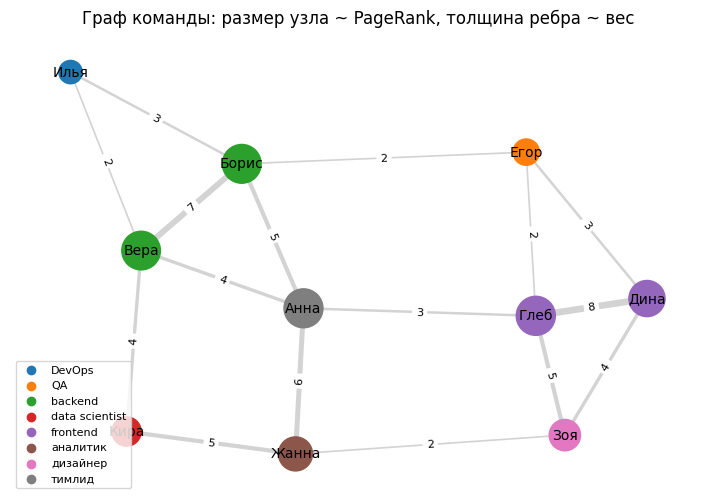

In [6]:
pos = nx.spring_layout(G, seed=7, weight="weight")
roles = sorted(set(people.values()))
cmap = plt.get_cmap("tab10")
node_colors = [cmap(roles.index(G.nodes[n]["role"])) for n in G.nodes()]
widths = [G[u][v]["weight"] * 0.6 for u, v in G.edges()]

plt.figure(figsize=(9, 6))
nx.draw_networkx_edges(G, pos, width=widths, edge_color="lightgray")
nx.draw_networkx_nodes(G, pos, node_color=node_colors,
                       node_size=[6000 * metrics.loc[n, "pagerank"] for n in G.nodes()])
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=8)
for r in roles:
    plt.scatter([], [], color=cmap(roles.index(r)), label=r)
plt.legend(loc="lower left", fontsize=8)
plt.title("Граф команды: размер узла ~ PageRank, толщина ребра ~ вес")
plt.axis("off")
plt.show()

**Вывод по части 1.** Граф связный, диаметр 4, плотность около 0.36. Наибольшие PageRank и посредничество у тимлида Анны
и у Бориса с Глебом: через них проходят связи между backend, frontend и аналитикой.
Алгоритмы сообществ выделяют «бэкенд + данные» и «фронтенд + дизайн + QA», то есть разбиение совпадает с реальной структурой команды.

## Часть 2. Датасеты и визуализации

### 2.1 Загрузка данных
Dolphins скачиваем с [KONECT](http://konect.cc/networks/dolphins/) (старый адрес из ноутбука `konect.uni-koblenz.de` больше не работает).

In [7]:
URL = "http://konect.cc/files/download.tsv.dolphins.tar.bz2"
if not os.path.exists("dolphins/out.dolphins"):
    urllib.request.urlretrieve(URL, "dolphins.tar.bz2")
    with tarfile.open("dolphins.tar.bz2") as tar:
        tar.extractall()

D = nx.Graph()
with open("dolphins/out.dolphins") as f:
    for line in f:
        if line.startswith("%"):
            continue
        u, v = line.split()[:2]
        D.add_edge(int(u), int(v))

L = nx.les_miserables_graph()   # взвешенный граф персонажей "Отверженных"

for name, g in [("Dolphins", D), ("Les Misérables", L)]:
    print("{:15s} узлов={:3d} рёбер={:3d} плотность={:.3f} кластеризация={:.3f} диаметр={} ассортативность={:.3f}".format(
        name, g.number_of_nodes(), g.number_of_edges(), nx.density(g), nx.average_clustering(g),
        nx.diameter(g), nx.degree_pearson_correlation_coefficient(g)))

Dolphins        узлов= 62 рёбер=159 плотность=0.084 кластеризация=0.259 диаметр=8 ассортативность=-0.044
Les Misérables  узлов= 77 рёбер=254 плотность=0.087 кластеризация=0.573 диаметр=5 ассортативность=-0.165


In [8]:
def centralities(g, weight=None):
    df = pd.DataFrame({
        "degree": dict(g.degree()),
        "betweenness": nx.betweenness_centrality(g),
        "closeness": nx.closeness_centrality(g),
        "eigenvector": nx.eigenvector_centrality(g, max_iter=1000),
        "pagerank": nx.pagerank(g, weight=weight),
    })
    return df.round(3).sort_values("pagerank", ascending=False)

cD = centralities(D)
cL = centralities(L, weight="weight")
display(cD.head(5))
display(cL.head(5))

,degree,betweenness,closeness,eigenvector,pagerank
18,9,0.114,0.310,0.018,0.032
15,12,0.062,0.377,0.316,0.032
52,10,0.085,0.330,0.211,0.031
46,11,0.041,0.347,0.285,0.030
38,11,0.139,0.399,0.301,0.030


,degree,betweenness,closeness,eigenvector,pagerank
Valjean,36,0.570,0.644,0.268,0.100
Marius,19,0.132,0.531,0.259,0.052
Myriel,10,0.177,0.429,0.028,0.039
Cosette,11,0.024,0.478,0.111,0.037
Enjolras,15,0.043,0.481,0.267,0.037


### 2.2 Разные укладки (layouts) графа дельфинов
Одни и те же данные выглядят совершенно по-разному в зависимости от алгоритма укладки.

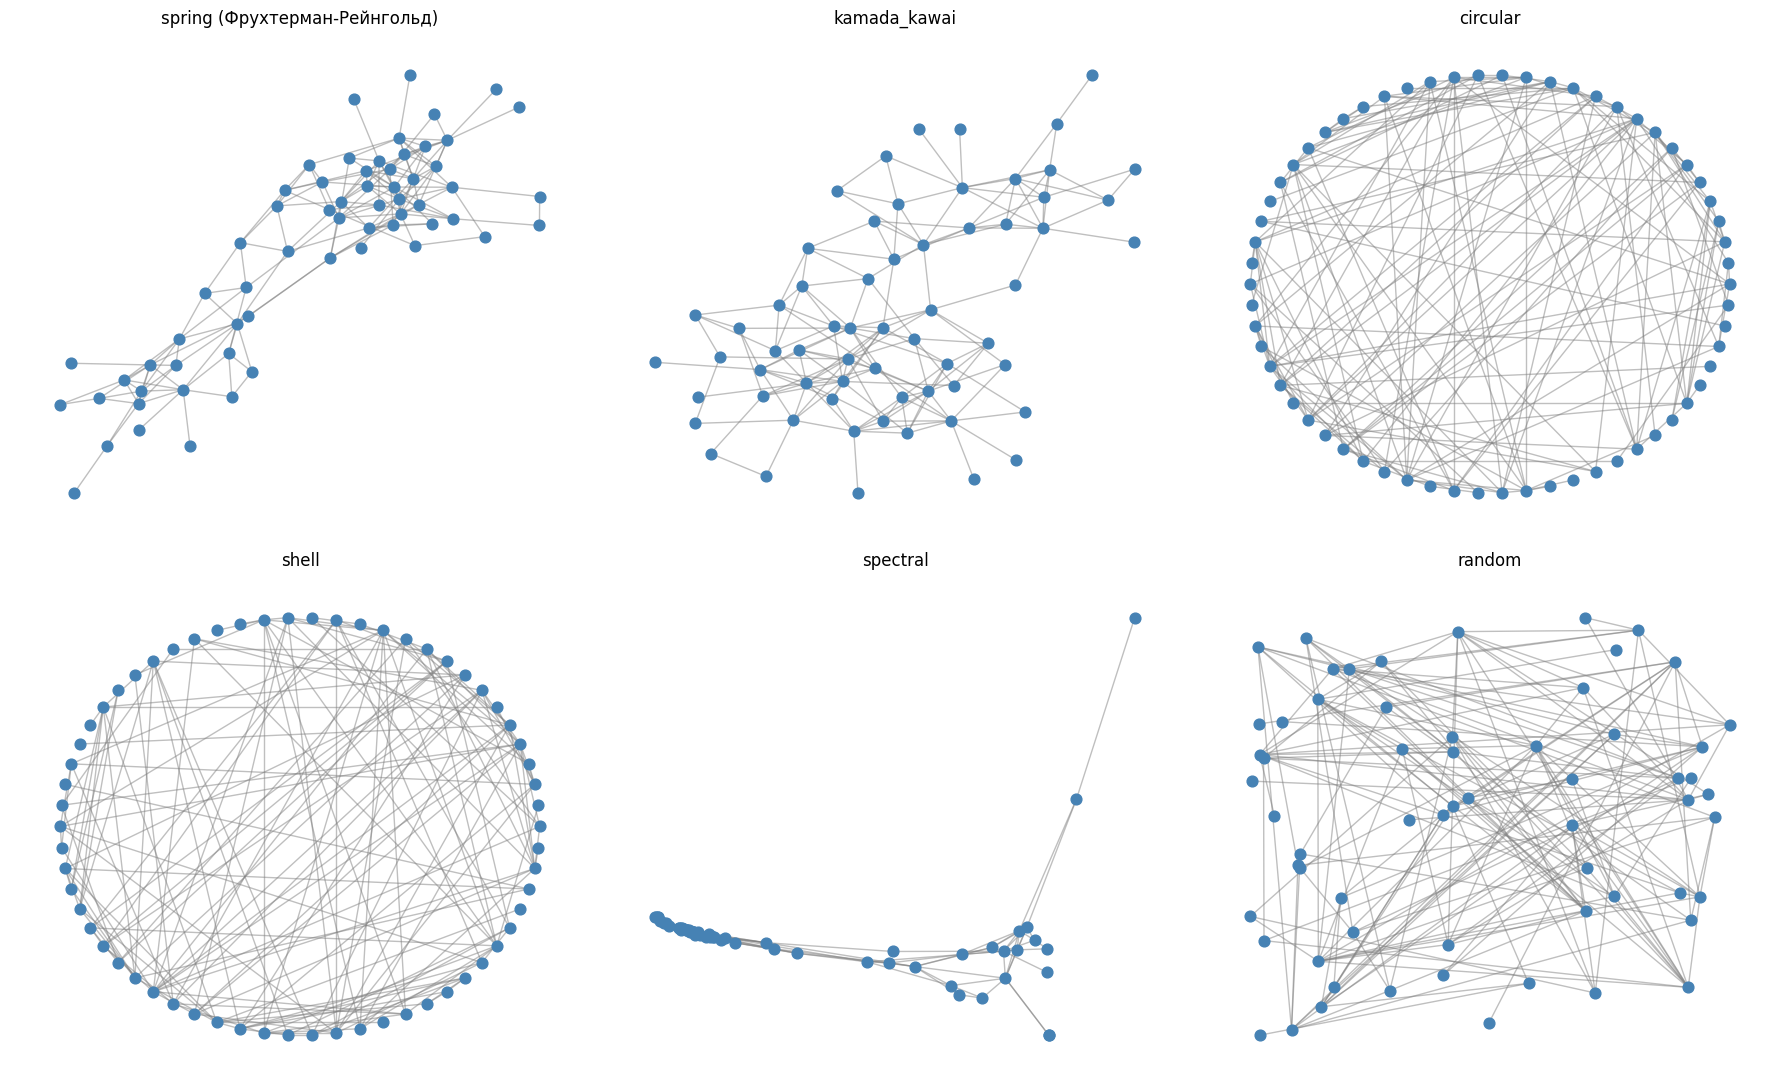

In [9]:
layouts = {
    "spring (Фрухтерман-Рейнгольд)": nx.spring_layout(D, seed=1),
    "kamada_kawai": nx.kamada_kawai_layout(D),
    "circular": nx.circular_layout(D),
    "shell": nx.shell_layout(D),
    "spectral": nx.spectral_layout(D),
    "random": nx.random_layout(D, seed=1),
}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (title, p) in zip(axes.ravel(), layouts.items()):
    nx.draw_networkx_edges(D, p, ax=ax, edge_color="gray", alpha=0.5)
    nx.draw_networkx_nodes(D, p, ax=ax, node_size=60, node_color="steelblue")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.3 Сообщества и центральность
Сообщества ищем алгоритмом Лувена (максимизация модулярности). Размер узла пропорционален посредничеству (betweenness).

Dolphins: 5 сообществ, модулярность 0.519
Les Mis:  6 сообществ, модулярность 0.565


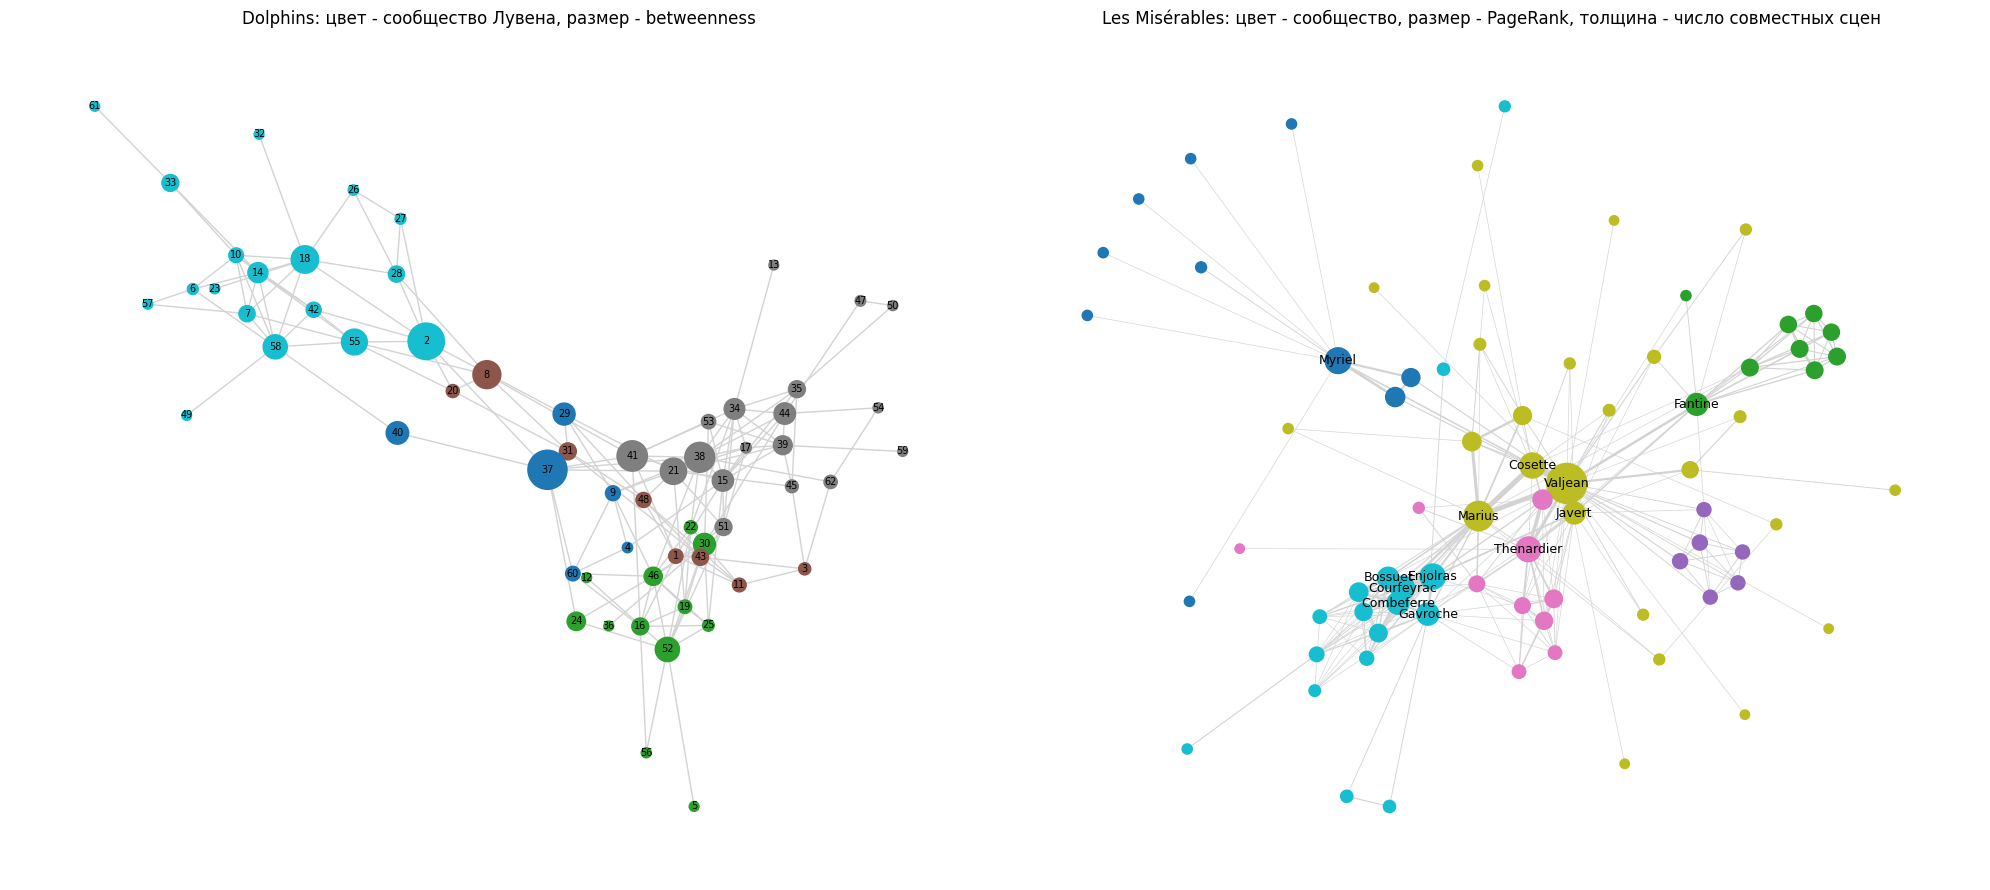

In [10]:
comms_D = community.louvain_communities(D, seed=42)
comms_L = community.louvain_communities(L, weight="weight", seed=42)
part_D = {n: i for i, c in enumerate(comms_D) for n in c}
part_L = {n: i for i, c in enumerate(comms_L) for n in c}
print("Dolphins: {} сообществ, модулярность {:.3f}".format(len(comms_D), community.modularity(D, comms_D)))
print("Les Mis:  {} сообществ, модулярность {:.3f}".format(len(comms_L), community.modularity(L, comms_L, weight="weight")))

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
pD = nx.spring_layout(D, seed=3)
nx.draw_networkx(D, pD, ax=axes[0], node_color=[part_D[n] for n in D], cmap="tab10",
                 node_size=[50 + 3000 * cD.loc[n, "betweenness"] for n in D],
                 edge_color="lightgray", font_size=7)
axes[0].set_title("Dolphins: цвет - сообщество Лувена, размер - betweenness")

pL = nx.spring_layout(L, seed=3, weight="weight", k=0.3)
w = np.array([d["weight"] for _, _, d in L.edges(data=True)])
nx.draw_networkx_edges(L, pL, ax=axes[1], width=0.3 + w / w.max() * 5, edge_color="lightgray")
nx.draw_networkx_nodes(L, pL, ax=axes[1], node_color=[part_L[n] for n in L], cmap="tab10",
                       node_size=[30 + 8000 * cL.loc[n, "pagerank"] for n in L])
top = set(cL.head(12).index)
nx.draw_networkx_labels(L, pL, ax=axes[1], labels={n: n for n in L if n in top}, font_size=9)
axes[1].set_title("Les Misérables: цвет - сообщество, размер - PageRank, толщина - число совместных сцен")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.4 Распределение степеней, матрица смежности, k-ядра

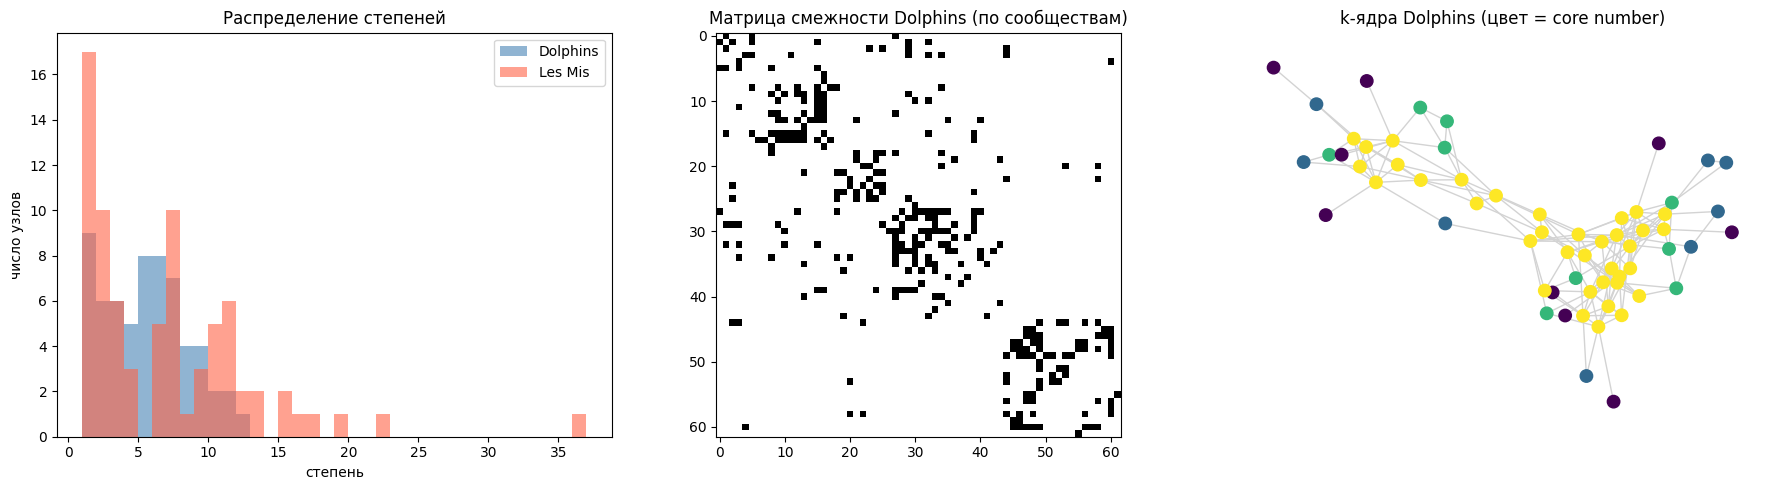

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for g, name, color in [(D, "Dolphins", "steelblue"), (L, "Les Mis", "tomato")]:
    deg = [d for _, d in g.degree()]
    axes[0].hist(deg, bins=range(1, max(deg) + 2), alpha=0.6, label=name, color=color)
axes[0].set_title("Распределение степеней")
axes[0].set_xlabel("степень"); axes[0].set_ylabel("число узлов"); axes[0].legend()

# Матрица смежности, узлы упорядочены по сообществам: видна блочная структура
order = [n for c in comms_D for n in sorted(c)]
A = nx.to_numpy_array(D, nodelist=order)
axes[1].imshow(A, cmap="Greys")
axes[1].set_title("Матрица смежности Dolphins (по сообществам)")

core = nx.core_number(D)
nx.draw_networkx(D, pD, ax=axes[2], node_color=[core[n] for n in D], cmap="viridis",
                 node_size=80, with_labels=False, edge_color="lightgray")
axes[2].set_title("k-ядра Dolphins (цвет = core number)")
axes[2].axis("off")
plt.tight_layout()
plt.show()

Кратчайший путь Napoleon -> Cosette: Napoleon -> Myriel -> Valjean -> Cosette


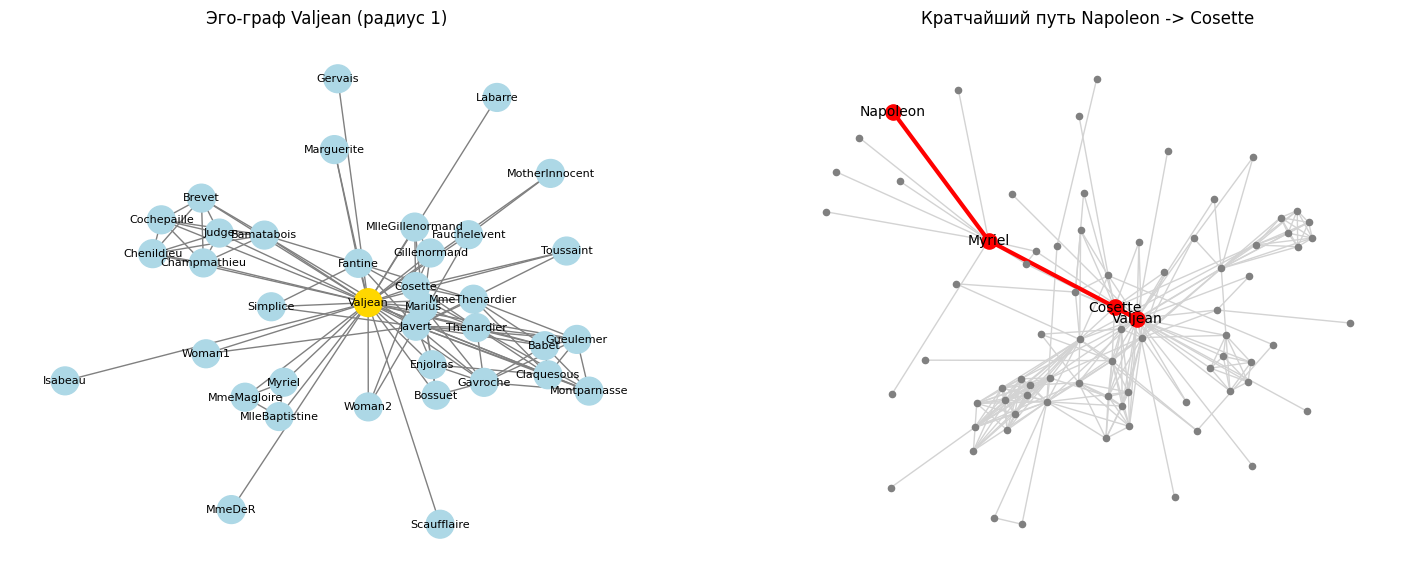

In [12]:
# Эго-граф главного персонажа и кратчайший путь между двумя персонажами
ego = nx.ego_graph(L, "Valjean", radius=1)
path = nx.shortest_path(L, "Napoleon", "Cosette")
print("Кратчайший путь Napoleon -> Cosette:", " -> ".join(path))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
pe = nx.spring_layout(ego, seed=2)
nx.draw_networkx(ego, pe, ax=axes[0], node_color=["gold" if n == "Valjean" else "lightblue" for n in ego],
                 node_size=400, font_size=8, edge_color="gray")
axes[0].set_title("Эго-граф Valjean (радиус 1)")
path_edges = list(zip(path, path[1:]))
nx.draw_networkx_edges(L, pL, ax=axes[1], edge_color="lightgray")
nx.draw_networkx_nodes(L, pL, ax=axes[1], node_size=20, node_color="gray")
nx.draw_networkx_edges(L, pL, ax=axes[1], edgelist=path_edges, edge_color="red", width=3)
nx.draw_networkx_nodes(L, pL, ax=axes[1], nodelist=path, node_color="red", node_size=120)
nx.draw_networkx_labels(L, pL, ax=axes[1], labels={n: n for n in path}, font_size=10)
axes[1].set_title("Кратчайший путь Napoleon -> Cosette")
for ax in axes:
    ax.axis("off")
plt.show()

### 2.5 Интерактивная визуализация: PyVis

PyVis генерирует HTML-страницу на основе библиотеки vis-network. Узлы можно перетаскивать и приближать,
при наведении показывается подсказка с метриками. HTML-файлы сохраняются рядом с ноутбуком, их можно открыть в браузере.

In [13]:
from pyvis.network import Network

def show_html_file(path, height=650):
    """Встраивает сохранённый HTML в ноутбук через iframe srcdoc."""
    with open(path, encoding="utf-8") as f:
        content = f.read()
    display(HTML('<iframe srcdoc="{}" width="100%" height="{}" style="border:1px solid #ddd"></iframe>'
                 .format(html.escape(content), height)))

palette = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46f0f0", "#f032e6", "#bcf60c", "#fabebe", "#008080"]

net = Network(height="600px", width="100%", bgcolor="#ffffff", notebook=True, cdn_resources="remote")
for n in L.nodes():
    net.add_node(n, label=n, color=palette[part_L[n] % len(palette)],
                 size=8 + 400 * cL.loc[n, "pagerank"],
                 title="{}\nстепень: {}\nPageRank: {:.3f}\nbetweenness: {:.3f}\nсообщество: {}".format(
                     n, cL.loc[n, "degree"], cL.loc[n, "pagerank"], cL.loc[n, "betweenness"], part_L[n]))
for u, v, d in L.edges(data=True):
    net.add_edge(u, v, value=d["weight"], title="совместных сцен: {}".format(d["weight"]))
net.barnes_hut(gravity=-6000, spring_length=120)
net.save_graph("les_miserables_pyvis.html")
show_html_file("les_miserables_pyvis.html")

In [14]:
# PyVis: граф дельфинов из networkx одной командой + панель настройки физики
net2 = Network(height="600px", width="100%", notebook=True, cdn_resources="remote", select_menu=False)
for n in D.nodes():
    D.nodes[n]["group"] = part_D[n]
    D.nodes[n]["title"] = "дельфин {}; степень {}; k-ядро {}".format(n, D.degree(n), core[n])
    D.nodes[n]["size"] = 6 + 2 * D.degree(n)
net2.from_nx(D)
net2.force_atlas_2based()
net2.show_buttons(filter_=["physics"])
net2.save_graph("dolphins_pyvis.html")
show_html_file("dolphins_pyvis.html", height=900)

### 2.6 Интерактивная визуализация: vis-network напрямую

Делаем то же самое без обёртки, на чистом JavaScript ([примеры vis-network](https://visjs.github.io/vis-network/examples/)).
Данные графа выгружаем из networkx в JSON. Используем иерархическую раскладку и кластеризацию сообществ:
**двойной клик** по кластеру раскрывает его, кнопка «Свернуть сообщества» снова собирает узлы в кластеры.

In [15]:
nodes_js = [{"id": n, "label": n, "group": part_L[n], "value": float(cL.loc[n, "pagerank"]),
             "title": "{} | PageRank {:.3f}".format(n, cL.loc[n, "pagerank"])} for n in L.nodes()]
edges_js = [{"from": u, "to": v, "value": d["weight"], "title": "сцен: {}".format(d["weight"])}
            for u, v, d in L.edges(data=True)]

template = """<!doctype html>
<html><head><meta charset="utf-8">
<script src="https://cdn.jsdelivr.net/npm/vis-network@9.1.9/standalone/umd/vis-network.min.js"></script>
<style>body{font-family:sans-serif;margin:0} #net{width:100%;height:560px;border-top:1px solid #ddd}
button{margin:6px;padding:4px 10px}</style></head>
<body>
<button onclick="clusterAll()">Свернуть сообщества</button>
<button onclick="network.setOptions({layout:{hierarchical:{enabled:true,direction:'UD',sortMethod:'hubsize'}}})">Иерархия</button>
<button onclick="network.setOptions({layout:{hierarchical:{enabled:false}}})">Физика</button>
<div id="net"></div>
<script>
const nodes = new vis.DataSet(__NODES__);
const edges = new vis.DataSet(__EDGES__);
const network = new vis.Network(document.getElementById("net"), {nodes, edges}, {
  nodes: {shape: "dot", scaling: {min: 6, max: 40}, font: {size: 12}},
  edges: {color: {opacity: 0.4}, scaling: {min: 1, max: 8}, smooth: false},
  physics: {solver: "forceAtlas2Based", stabilization: {iterations: 200}},
  interaction: {hover: true, navigationButtons: true}
});
const groups = [...new Set(__NODES__.map(n => n.group))];
function clusterAll() {
  groups.forEach(g => network.cluster({
    joinCondition: n => n.group === g,
    clusterNodeProperties: {id: "cluster_" + g, label: "сообщество " + g, shape: "database", group: g}
  }));
}
network.on("doubleClick", p => { if (p.nodes.length && network.isCluster(p.nodes[0])) network.openCluster(p.nodes[0]); });
</script></body></html>"""

page = template.replace("__NODES__", json.dumps(nodes_js, ensure_ascii=False)) \
               .replace("__EDGES__", json.dumps(edges_js, ensure_ascii=False))
with open("les_miserables_visjs.html", "w", encoding="utf-8") as f:
    f.write(page)
show_html_file("les_miserables_visjs.html", height=640)

## Выводы

1. Для собственного графа команды посчитаны основные характеристики: радиус, диаметр, плотность, ассортативность,
   кластеризация, центральности по степени, близости, посредничеству, собственному вектору и PageRank, а также сообщества.
   Граф сохранён в формате GEXF (можно открыть в Gephi).
2. **Dolphins** — разреженная сеть (плотность около 0.08) с выраженными сообществами (модулярность Лувена около 0.52).
   Ключевые «связные» дельфины выделяются по betweenness: на них держатся связи между группами.
3. **Les Misérables** — сеть с хабом (Valjean): у неё самые высокие PageRank и посредничество.
   Ассортативность отрицательная: второстепенные персонажи связаны с главными, а не друг с другом.
4. Выбор укладки сильно влияет на восприятие. Spring и Kamada-Kawai показывают сообщества,
   circular/shell подходят для небольших графов, random почти бесполезна.
5. Интерактивные визуализации (PyVis и vis-network) позволяют исследовать граф: подсказки с метриками,
   перетаскивание узлов, настройка физики, сворачивание сообществ в кластеры. Результаты сохранены в файлы
   `les_miserables_pyvis.html`, `dolphins_pyvis.html` и `les_miserables_visjs.html`.